In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", None)

column_types = {
    "id": "Int64",
    "osm_id": "str",
    "addr_street": "str",
    "addr_number": "str",
    "ground_floor_group": "str",
    "ground_floor_function": "str",
    "upper_floor_group": "str",
    "upper_floor_function": "str",
    "number_of_storeys": "Int64",
    "is_mixed_use": "boolean",
    "build_year_est": "Int64",
    "arch_style": "str",
    "condition": "Int64",
    "max_height": "float64",
    "is_heritage": "str",
    "source": "str",
    "confidence": "Int64",
    "date_of_checking": "str",
}

In [2]:
data_gdynia = pd.read_csv(
    "../data/processed/fixed/srodmiescie.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
    parse_dates=["date_of_checking"],
)
data_gdynia

,osm_id,addr_street,addr_number,ground_floor_group,ground_floor_function,upper_floor_group,upper_floor_function,number_of_storeys,is_mixed_use,build_year_est,arch_style,condition,max_height,is_heritage,source,confidence,date_of_checking,number_of_functions
id,,,,,,,,,,,,,,,,,,
1,127184291,Świętego Piotra,8,NaN,hotel,NaN,Hotel,7,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
2,890729731,Świętego Piotra,6D,NaN,mieszkaniowa wielorodzinna,NaN,Mieszkaniowa Wielorodzinna,5,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
3,890292040,Węglowa,22,NaN,centrum handlowe,NaN,Mieszkaniowa Wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
4,890729732,Świętego Piotra,6,NaN,mieszkaniowa wielorodzinna,NaN,Mieszkaniowa Wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
5,136885205,Tadeusza Wendy,15,NaN,centrum medyczne,NaN,Centrum Medyczne,6,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,2,2026-09-27,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1237,126180359,Władysława IV,61,NaN,"laboratorium medyczne,piekarnia,kiosk",NaN,Mieszkaniowa Wielorodzinna,7,<NA>,1940,modernizm,3,NaN,NaN,google.com/maps,2,2026-09-30,3
1238,126173503,Świętojańska,122,NaN,"apteka,handel zdrowie",NaN,Biurowa,6,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-30,2
1239,260676369,Aleja Marszałka Józefa Piłsudskiego,56,NaN,mieszkaniowa wielorodzinna,NaN,Mieszkaniowa Wielorodzinna,7,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-30,1


In [3]:
data_gdynia_long = pd.read_csv(
    "../data/processed/fixed/srodmiescie_long.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
)
data_gdynia_long.head()

,addr_street,ground_floor_function
id,,
1,Świętego Piotra,hotel
2,Świętego Piotra,mieszkaniowa wielorodzinna
3,Węglowa,centrum handlowe
4,Świętego Piotra,mieszkaniowa wielorodzinna
5,Tadeusza Wendy,centrum medyczne


1.

In [4]:
build_per_style = (
    data_gdynia.groupby("arch_style").agg("size").sort_values(ascending=False)
)

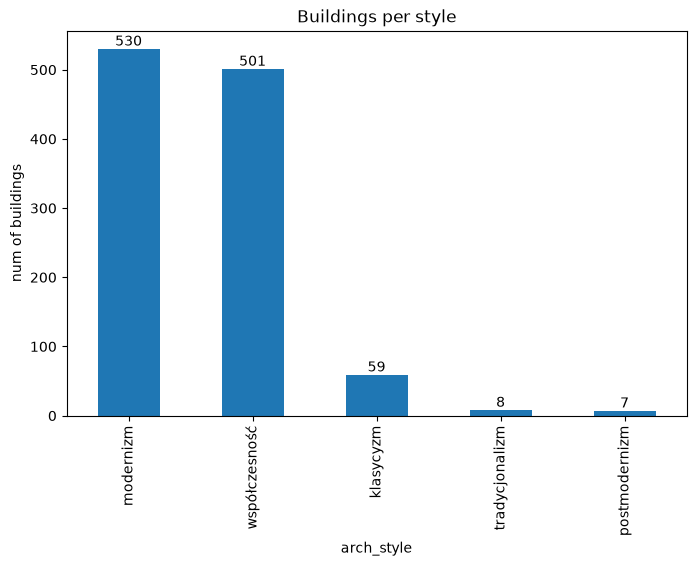

In [5]:
fig1, ax1 = plt.subplots(figsize=(8, 5))

build_per_style.plot.bar(ax=ax1)

ax1.set_title("Buildings per style")
ax1.set_ylabel("num of buildings")
ax1.set_xlabel("arch_style")
ax1.bar_label(ax1.containers[0])

plt.show()

In [ ]:
assert len(ax1.patches) == len(build_per_style)

# height = [p.get_height() for p in ax1.patches]
height = []
for p in ax1.patches:
    height.append(p.get_height())

assert height == build_per_style.tolist()


2.

In [7]:
def only_big_streets(df, min_build):
    return df.loc[df.groupby("addr_street").transform("size") >= min_build]


build_num_streets = (
    data_gdynia.pipe(only_big_streets, min_build=20)
    .groupby("addr_street")
    .agg("size")
    .sort_values(ascending=True)
)

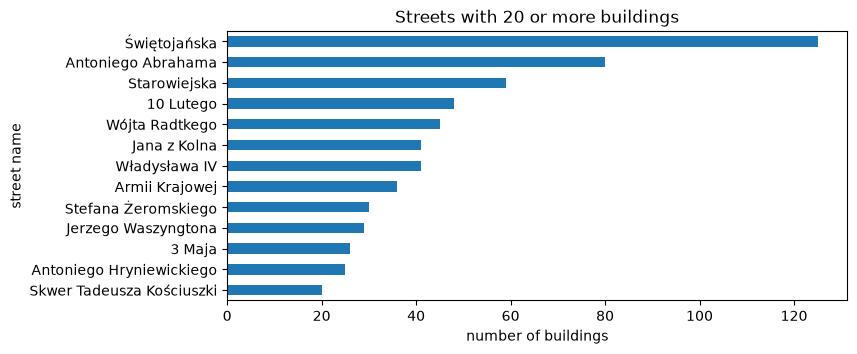

In [8]:
fig2, ax2 = plt.subplots(figsize=(8, 3.5))

build_num_streets.plot.barh(ax=ax2)

ax2.set_title("Streets with 20 or more buildings")
ax2.set_xlabel("number of buildings")
ax2.set_ylabel("street name")

plt.show()

In [9]:
assert len(ax2.patches) == len(build_num_streets)
width = [p.get_width() for p in ax2.patches]
assert width == build_num_streets.tolist()

3.

In [10]:
num_storeys = data_gdynia["number_of_storeys"].value_counts().sort_index()
num_storeys

number_of_storeys
1     426
2      74
3      42
4      43
5     161
6     242
7      58
8      14
9      16
10     11
11     11
12      3
13      1
17      2
38      1
Name: count, dtype: Int64

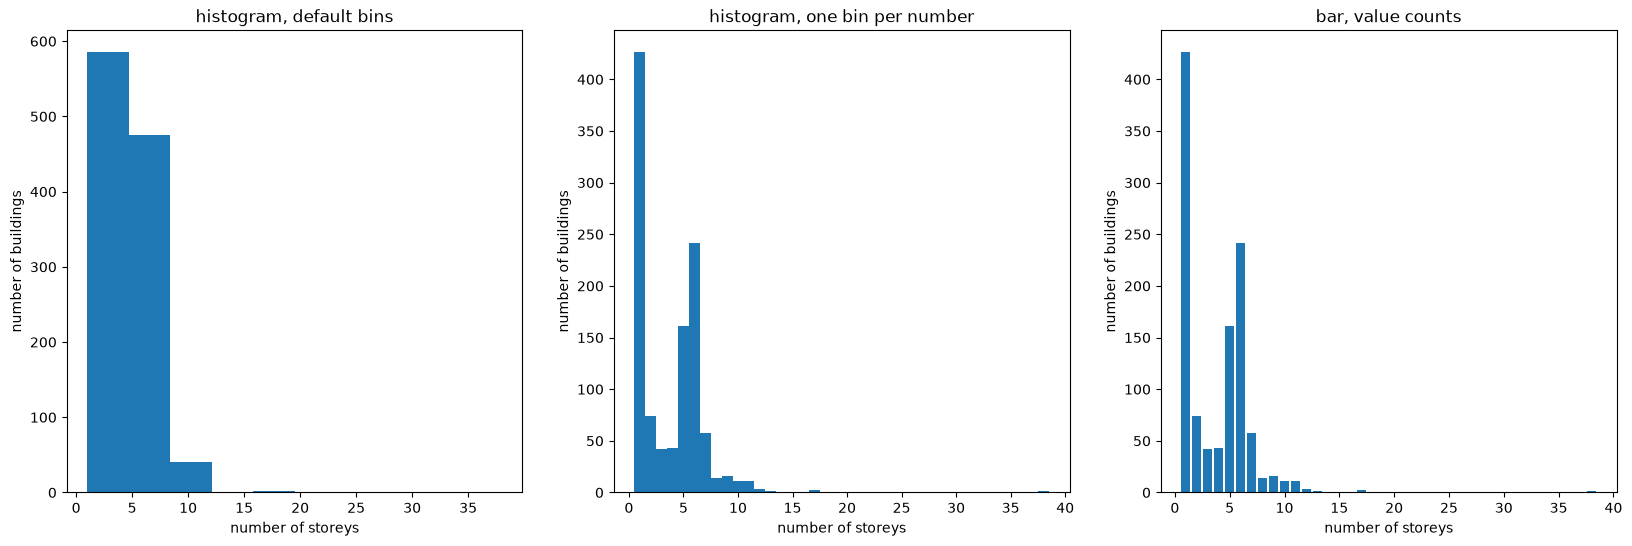

In [ ]:
fig3, ax3 = plt.subplots(1, 3, figsize=(20, 6))

ax3[0].hist(data_gdynia["number_of_storeys"])
ax3[1].hist(data_gdynia["number_of_storeys"], bins=np.arange(0.5, 39.5))
ax3[2].bar(num_storeys.index, num_storeys.values)


ax3[0].set_title("histogram, default bins")
ax3[1].set_title("histogram, one bin per number")
ax3[2].set_title("bar, value counts")

for ax in ax3:
    ax.set_xlabel("number of storeys")

for ax in ax3:
    ax.set_ylabel("number of buildings")

plt.show()

In [ ]:
height2 = []
for p in ax3[1].patches:
    height2.append(p.get_height())

assert sum(height2) == len(data_gdynia)
assert height2[0] == 426
assert height2[5] == 242
height2 = np.array(height2)
assert (height2[height2 > 0] == num_storeys.values).all()


height3 = []
for p in ax3[2].patches:
    height3.append(p.get_height())

height3 = np.array(height3)
assert np.array_equal(height3, num_storeys.to_list())

4.

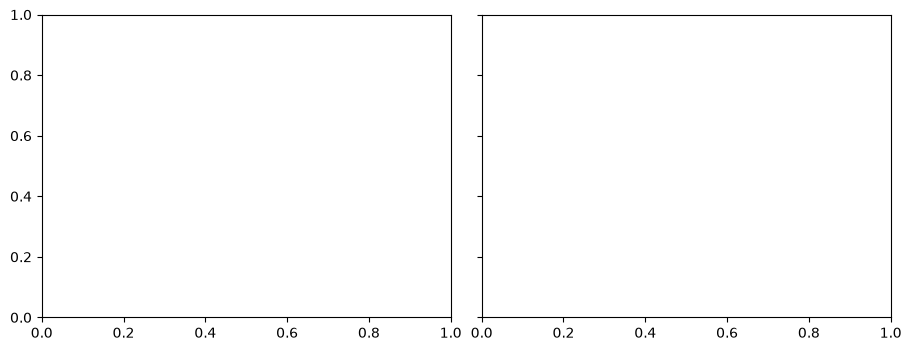

In [ ]:
fig4, ax4 = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, layout="constrained")